Observations : 420,768
Stations : 12
Période : 2013-03-01 00:00:00 — 2017-02-28 23:00:00
Statistiques descriptives des variables numériques :


,count,mean,std,min,25%,50%,75%,max
pm25,412029.0,79.79,80.82,2.00,20.0,55.0,111.0,999.0
PM10,414319.0,104.60,91.77,2.00,36.0,82.0,145.0,999.0
SO2,411747.0,15.83,21.65,0.29,3.0,7.0,20.0,500.0
NO2,408652.0,50.64,35.13,1.03,23.0,43.0,71.0,290.0
CO,400067.0,1230.77,1160.18,100.00,500.0,900.0,1500.0,10000.0
O3,407491.0,57.37,56.66,0.21,11.0,45.0,82.0,1071.0
TEMP,420370.0,13.54,11.44,-19.90,3.1,14.5,23.3,41.6
PRES,420375.0,1010.75,10.47,982.40,1002.3,1010.4,1019.0,1042.8
DEWP,420365.0,2.49,13.79,-43.40,-8.9,3.1,15.1,29.1
RAIN,420378.0,0.06,0.82,0.00,0.0,0.0,0.0,72.5


,observations,moyenne,mediane,ecart_type
station,,,,
Dongsi,34314,86.19,61.0,86.58
Wanshouxigong,34368,85.02,60.0,85.98
Nongzhanguan,34436,84.84,59.0,86.23
Gucheng,34418,83.85,60.0,82.80
Wanliu,34682,83.37,59.0,81.91
Guanyuan,34448,82.93,59.0,80.93
Aotizhongxin,34139,82.77,58.0,82.14
Tiantan,34387,82.16,59.0,80.92
Shunyi,34151,79.49,55.0,81.23


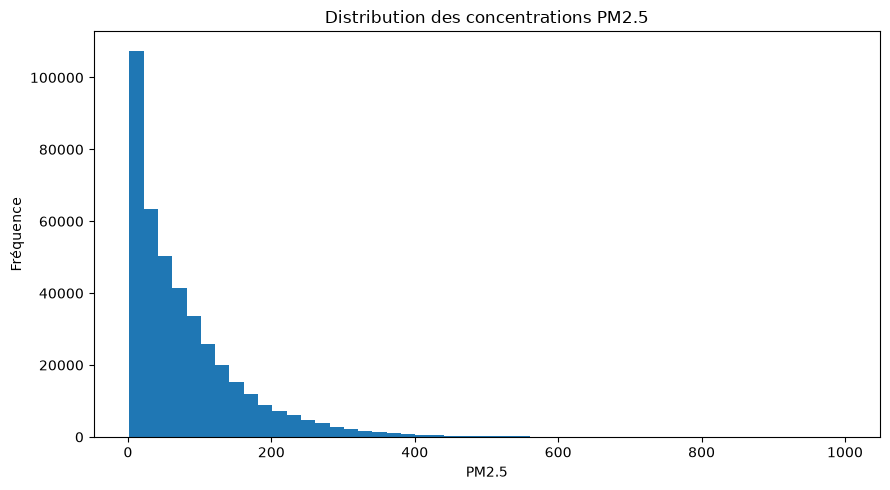

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

data_file = Path(
    r"C:\Users\ADMIN\Desktop\AirWatch\analytics\outputs\prepared_data\observations_clean.parquet"
)
df = pd.read_parquet(data_file)

pollutants = ["pm25", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
available = [column for column in pollutants if column in df.columns]

print(f"Observations : {len(df):,}")
print(f"Stations : {df['station'].nunique()}")
print(f"Période : {df['event_time'].min()} — {df['event_time'].max()}")

print("Statistiques descriptives des variables numériques :")
display(df[available].describe().T.round(2))

station_summary = (
    df.groupby("station")["pm25"]
    .agg(observations="count", moyenne="mean", mediane="median", ecart_type="std")
    .sort_values("moyenne", ascending=False)
    .round(2)
)
display(station_summary)

df["pm25"].dropna().plot.hist(bins=50, figsize=(9, 5))
plt.title("Distribution des concentrations PM2.5")
plt.xlabel("PM2.5")
plt.ylabel("Fréquence")
plt.tight_layout()
plt.show()